# 07 - Model comparison

All ten families under grouped nested CV (primary) with random nested CV as a reference.
Selection is by grouped MAE, not by the highest R2.

In [1]:
import json, sys, pathlib
import numpy as np, pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

ROOT = pathlib.Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

METRICS = ROOT / "evaluation" / "metrics"
PRED = ROOT / "evaluation" / "predictions"
PLOTS = ROOT / "evaluation" / "plots"
ERRORS = ROOT / "evaluation" / "error_analysis"

pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 40)

def show(path):
    try:
        from IPython.display import Image, display
        display(Image(filename=str(path)))
    except Exception:
        print("plot written to", path)


## Ranked comparison

In [2]:
comparison = pd.read_csv(METRICS / "phase3_model_comparison.csv")
columns = ["rank", "model", "mae_mean", "mae_sd", "rmse_mean", "r2_mean", "spearman_mean", "random_mae_mean"]
for configuration in comparison["configuration"].unique():
    subset = comparison[comparison["configuration"] == configuration].sort_values("rank")
    print(configuration)
    print(subset[columns].round(3).to_string(index=False))
    print()

A_primary_640
 rank                  model  mae_mean  mae_sd  rmse_mean  r2_mean  spearman_mean  random_mae_mean
    1                svr_rbf     2.029   0.166      2.614    0.170          0.463            1.326
    2            extra_trees     2.092   0.140      2.670    0.163          0.503            1.359
    3          random_forest     2.113   0.176      2.704    0.139          0.472            1.511
    4 hist_gradient_boosting     2.144   0.259      2.727    0.091          0.463            1.415
    5                    knn     2.164   0.383      2.807    0.012          0.447            1.335
    6                  ridge     2.188   0.240      2.796    0.071          0.448            1.673
    7            elastic_net     2.254   0.326      2.906   -0.042          0.437            1.665
    8      gradient_boosting     2.259   0.272      2.915   -0.012          0.444            1.447
    9             dummy_mean     2.440   0.166      3.149   -0.137            NaN            2.

## Grouped MAE with fold-to-fold spread

Red bars are the selected model per configuration. Error bars are the SD across the five held-out state folds.

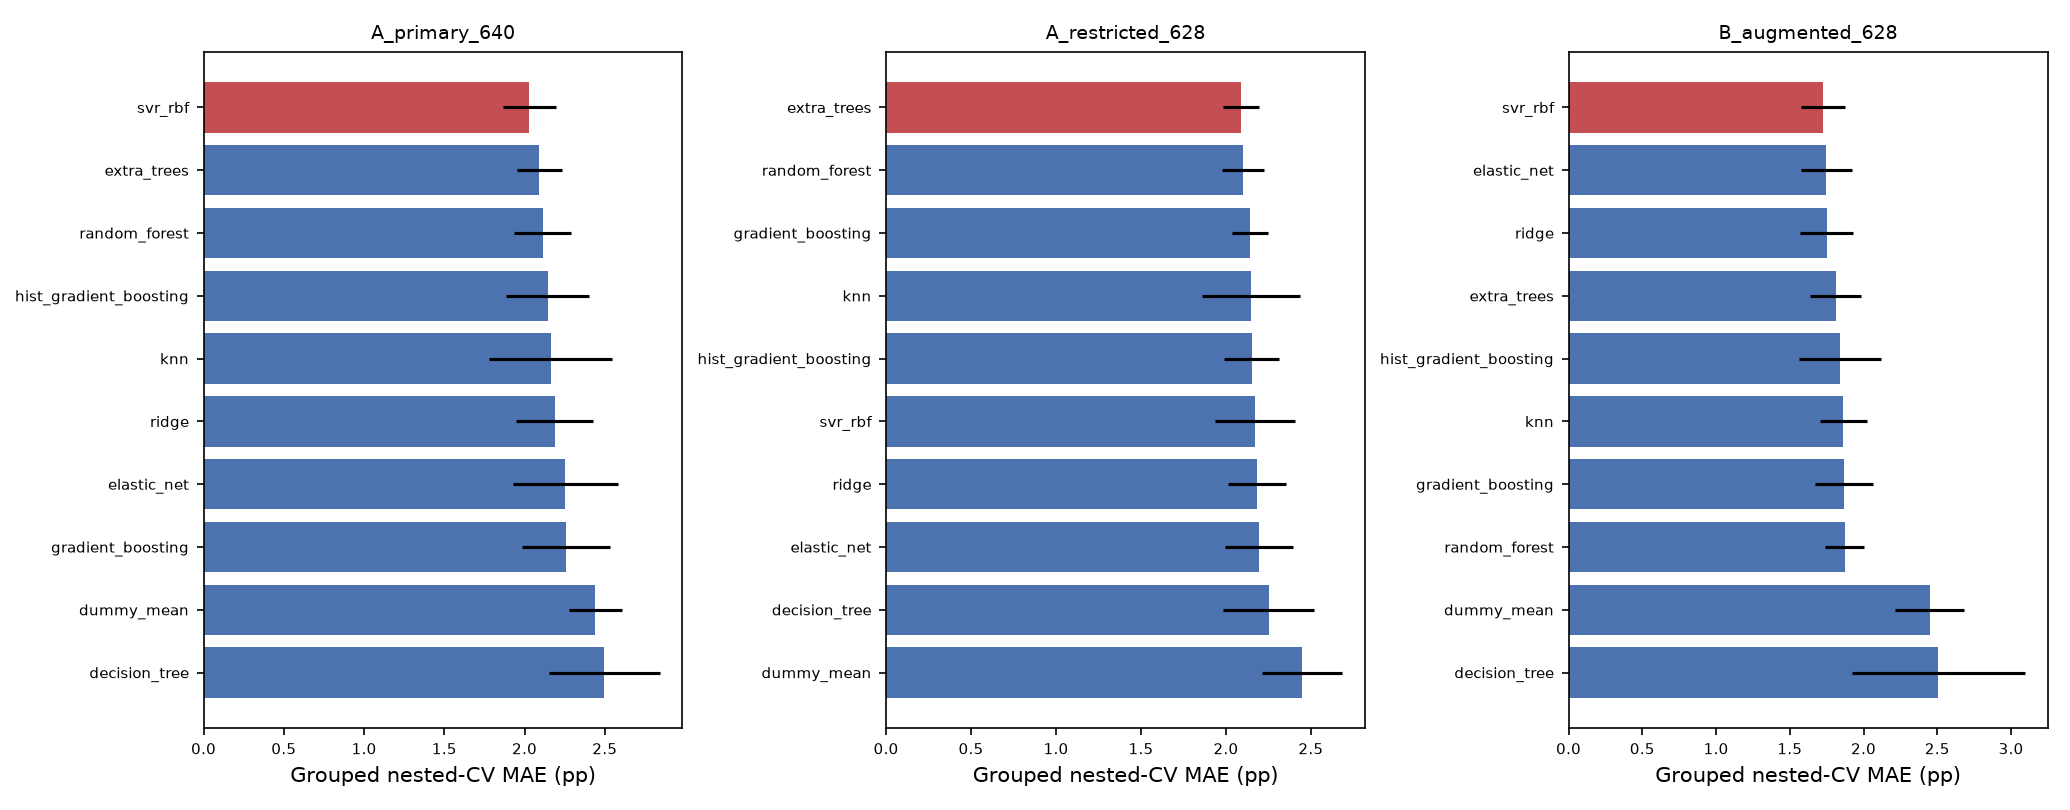

In [3]:
from src.evaluation import error_analysis as ea

path = PLOTS / "phase3_model_comparison_grouped.png"
ea.plot_model_comparison(comparison, path)
show(path)

## Selected model per configuration

In [4]:
selected = pd.read_csv(METRICS / "phase3_selected_models.csv")
selected[
    ["configuration", "model", "mae_mean", "mae_sd", "rmse_mean", "r2_mean",
     "spearman_mean", "random_mae_mean", "beats_phase2_knn", "complexity_rank"]
].round(3)

,configuration,model,mae_mean,mae_sd,rmse_mean,r2_mean,spearman_mean,random_mae_mean,beats_phase2_knn,complexity_rank
0,A_primary_640,svr_rbf,2.029,0.166,2.614,0.170,0.463,1.326,True,5
1,A_restricted_628,extra_trees,2.089,0.108,2.654,0.184,0.497,1.370,True,6
2,B_augmented_628,svr_rbf,1.725,0.151,2.256,0.399,0.626,1.140,True,5


## Configuration A versus B on identical districts and folds

Negative delta means Configuration B had the lower fold MAE. Five folds make this descriptive, not a significance test.

                 model  a_mae  b_mae  delta_mean  delta_sd  b_better_folds  n_folds  delta_pct
           elastic_net  2.196  1.748      -0.449     0.124               5        5    -20.429
               svr_rbf  2.171  1.725      -0.447     0.166               5        5    -20.564
                 ridge  2.185  1.749      -0.435     0.104               5        5    -19.935
hist_gradient_boosting  2.151  1.841      -0.309     0.269               4        5    -14.382
                   knn  2.146  1.863      -0.283     0.256               5        5    -13.173
           extra_trees  2.089  1.810      -0.279     0.090               5        5    -13.344
     gradient_boosting  2.143  1.868      -0.275     0.168               5        5    -12.831
         random_forest  2.099  1.871      -0.228     0.063               5        5    -10.874
            dummy_mean  2.450  2.450       0.000     0.000               0        5      0.000
         decision_tree  2.253  2.506       0.253  

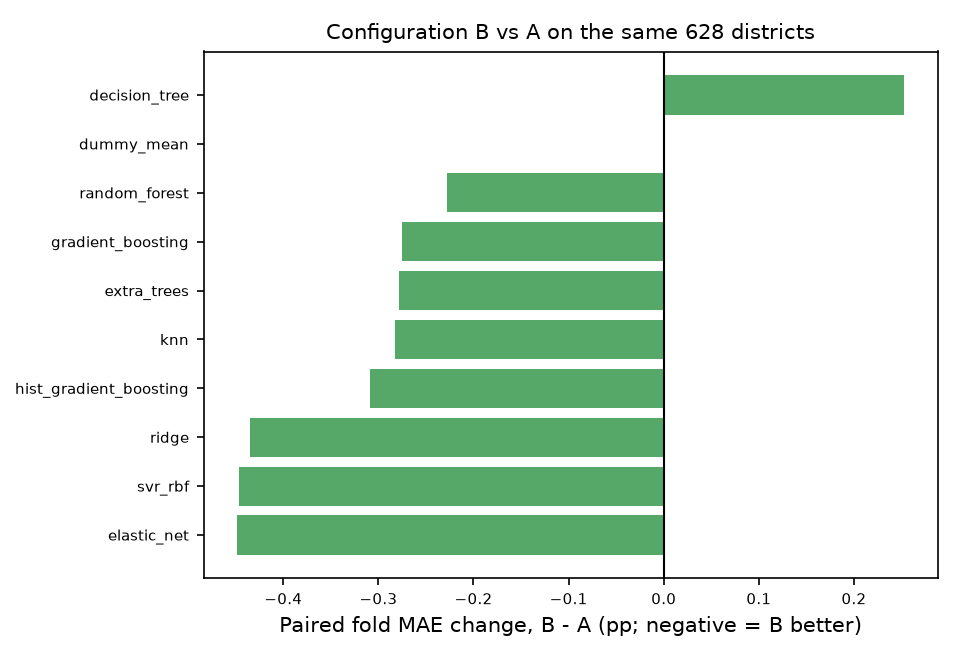

In [5]:
ab = pd.read_csv(METRICS / "phase3_ab_comparison.csv")
print(ab.round(3).to_string(index=False))
print()
print("models with B better in >= 4 of 5 folds:", int((ab["b_better_folds"] >= 4).sum()), "of", len(ab))
path = PLOTS / "phase3_ab_comparison.png"
ea.plot_ab_comparison(ab, path)
show(path)

## What the random-CV column is for

Random CV shares districts between folds, so it measures interpolation within the observed state mix. It quantifies how much of the apparent accuracy is state context; it is never the generalisation estimate.

In [6]:
primary = pd.read_csv(METRICS / "phase3_nested_cv_results.csv")
reference = pd.read_csv(METRICS / "phase3_random_cv_results.csv")
merged = primary.merge(reference, on=["configuration", "model"], suffixes=("_grouped", "_random"))
merged["mae_gap_pp"] = merged["mae_mean_random"] - merged["mae_mean_grouped"]
merged.groupby("configuration")["mae_gap_pp"].describe().round(3)

,count,mean,std,min,25%,50%,75%,max
configuration,,,,,,,,
A_primary_640,10.0,-0.613,0.230,-0.829,-0.732,-0.653,-0.588,-0.028
A_restricted_628,10.0,-0.575,0.240,-0.832,-0.714,-0.643,-0.502,-0.023
B_augmented_628,10.0,-0.482,0.208,-0.720,-0.596,-0.574,-0.366,-0.023
